# 14 · EdNet-KT1: results

Supports thesis Sections 4.4 (results), 4.5 (learning curve) and 4.7 (discussion). Reads only saved outputs (test-fold metrics, hardening, per-answer predictions, training logs); trains nothing.

Every model was trained with one configuration, untuned, three seeds; AUC is on held-out learners. All numbers are recomputed here from the files.

**Where to run.** Locally (recommended): `.venv-kt` with `requirements-analysis.txt`, started from the repository; no GPU needed.
**On Colab (CPU runtime is enough):** upload `ednet_colab_bundle.zip` (built by `knowledge_tracing/make_colab_bundle.py`) to `MyDrive/ednet_kt1/`; the training runs already live in `MyDrive/ednet_kt1/data/benchmarks/` (for the English run, upload `data/benchmarks/english_kt/` there too). Then *Runtime → Run all*: the first cell mounts Drive, unpacks the bundle and links the benchmark folder. Figures and tables are written to `data/benchmarks/report/` (on Drive when on Colab).

In [1]:
import sys, os
if "google.colab" in sys.modules:
    !pip install -q seaborn
from pathlib import Path
_root = Path.cwd().resolve()
while not (_root / "knowledge_tracing").is_dir() and _root.parent != _root:
    _root = _root.parent
if "google.colab" in sys.modules and not (_root / "knowledge_tracing").is_dir():
    import zipfile
    from google.colab import drive
    drive.mount("/content/drive")
    import time as _t
    with zipfile.ZipFile("/content/drive/MyDrive/ednet_kt1/ednet_colab_bundle.zip") as zf:
        for _i in zf.infolist():   # keep the zip's timestamps: the runner compares mtimes
            _p = zf.extract(_i, "/content/ednet")
            _m = _t.mktime(_i.date_time + (0, 0, -1))
            os.utime(_p, (_m, _m))
    _root = Path("/content/ednet")
sys.path[:0] = [str(_root), str(_root / "knowledge_tracing")]
import report_utils as ru
ROOT = ru.setup()
ru.style()
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
pd.set_option("display.width", 160, "display.max_columns", 30)
print("repository:", ROOT)

repository: /home/rene/MicroLearningThesis


In [2]:
import analysis
from kt_results import model_summary, hardening_tables, per_answer_frame, reliability
M = ru.MODELS
L = ru.MODEL_LABEL
BENCH = ru.ednet_bench_dir()
SIZES = [300, 1000, 2000, 5000, 10000, 20000]
MAIN = 5000
print("benchmark folder:", BENCH)

benchmark folder: data/benchmarks


## 1. Test-fold metrics per cohort (mean ± sd over seeds)

In [3]:
tabs = []
for n in SIZES:
    ev = BENCH / f"ednet_kt1_{n}/kt/artifacts/evaluation"
    if (ev / "test_comparison.csv").exists():
        t = model_summary(ev / "test_comparison.csv"); t.insert(0, "learners", n); tabs.append(t)
per_cohort = pd.concat(tabs, ignore_index=True)
display(per_cohort)
main = per_cohort[per_cohort["learners"] == MAIN].drop(columns="learners")
ru.save_table(main, "ednet_main_models", f"Deep KT models on the EdNet-KT1 cohort of {MAIN:,} learners (test fold, 3 seeds)",
              "tab:ednet-main-models", digits=4, size="footnotesize")

,learners,model,AUC,AUC sd,Accuracy,Log loss,valid AUC,best epoch
0,300,DKT,0.653219,0.005738,0.666611,0.620936,0.673411,14.000000
1,300,SAKT,0.624783,0.007340,0.659038,0.632704,0.660977,8.333333
2,300,AKT,0.671934,0.004240,0.668671,0.612556,0.681608,25.333333
3,300,DKVMN,0.652319,0.011032,0.657924,0.623903,0.676583,24.000000
4,300,SAINT,0.640931,0.003407,0.667224,0.622453,0.639406,19.000000
5,1000,DKT,0.676504,0.001127,0.655839,0.620386,0.682374,6.666667
6,1000,SAKT,0.648311,0.003536,0.647509,0.634762,0.667204,13.333333
7,1000,AKT,0.705444,0.002852,0.676143,0.627848,0.711384,34.333333
8,1000,DKVMN,0.672239,0.002014,0.656369,0.623516,0.674941,18.666667
9,1000,SAINT,0.655409,0.000937,0.652315,0.629593,0.661564,11.666667


table  -> data/benchmarks/report/tables/ednet_main_models.tex


## 2. Baselines, intervals and paired differences (hardening)

In [4]:
hm, ci, paired = hardening_tables(BENCH / f"ednet_kt1_{MAIN}/kt/artifacts/evaluation")
display(hm); display(ci); display(paired)
ru.save_table(hm, "ednet_hardening_metrics", f"All predictors on the same test targets ({MAIN:,} cohort; deep models: predictions averaged over 3 seeds)",
              "tab:ednet-hardening", digits=4, size="footnotesize")
ru.save_table(paired, "ednet_paired", f"Paired AUC differences, learner bootstrap ({MAIN:,} cohort)",
              "tab:ednet-paired", digits=4, align="lrrrr")

,predictor,AUC,Accuracy,Log loss,Brier,ECE (10 bins)
0,KC mean,0.6310,0.6300,0.6459,0.2271,0.0042
1,Item mean,0.7121,0.6755,0.6030,0.2077,0.0121
2,Logistic regression,0.7321,0.6868,0.5891,0.2018,0.0031
3,BKT default,0.5792,0.5373,0.6964,0.2494,0.1122
4,BKT fitted,0.6503,0.6428,0.6368,0.2228,0.0084
5,DKT,0.6893,0.6635,0.6160,0.2135,0.0058
6,SAKT,0.6746,0.6569,0.6241,0.2171,0.0137
7,AKT,0.7476,0.6981,0.5812,0.1975,0.0214
8,DKVMN,0.6881,0.6630,0.6168,0.2139,0.0035
9,SAINT,0.6705,0.6564,0.6252,0.2176,0.0144


,predictor,AUC,CI95_low,CI95_high
0,KC mean,0.6310,0.6246,0.6372
1,Item mean,0.7121,0.7063,0.7182
2,Logistic regression,0.7321,0.7268,0.7375
3,BKT default,0.5792,0.5742,0.5843
4,BKT fitted,0.6503,0.6448,0.6560
5,DKT,0.6893,0.6833,0.6955
6,SAKT,0.6746,0.6682,0.6812
7,AKT,0.7476,0.7428,0.7524
8,DKVMN,0.6881,0.6818,0.6943
9,SAINT,0.6705,0.6637,0.6777


,A - B,AUC diff,CI95_low,CI95_high,P(A>B)
0,AKT − DKT,0.0583,0.0543,0.0623,1.000
1,AKT − SAKT,0.0730,0.0681,0.0780,1.000
2,DKT − SAKT,0.0147,0.0117,0.0179,1.000
3,AKT − Logistic regression,0.0155,0.0133,0.0175,1.000
4,DKT − Logistic regression,-0.0428,-0.0471,-0.0387,0.000
5,SAKT − Logistic regression,-0.0575,-0.0629,-0.0523,0.000
6,AKT − BKT fitted,0.0973,0.0924,0.1019,1.000
7,DKT − BKT fitted,0.0390,0.0348,0.0430,1.000
8,BKT fitted − BKT default,0.0711,0.0660,0.0757,1.000
9,BKT fitted − kc_mean,0.0193,0.0160,0.0226,1.000


table  -> data/benchmarks/report/tables/ednet_hardening_metrics.tex
table  -> data/benchmarks/report/tables/ednet_paired.tex


## 3. Learning curve (test AUC vs cohort size)

cohort,300,1000,2000,5000,10000,20000
model,,,,,,
AKT,0.6719,0.7054,0.7233,0.7455,0.7536,0.7633
BKT default,0.5923,0.5804,0.5800,0.5792,0.5778,0.5787
BKT fitted,0.6415,0.6500,0.6463,0.6503,0.6494,0.6492
DKT,0.6532,0.6765,0.6754,0.6858,0.6861,0.6931
DKVMN,0.6523,0.6722,0.6745,0.6853,0.6846,0.6930
SAINT,0.6409,0.6554,0.6542,0.6656,0.7264,0.7526
SAKT,0.6248,0.6483,0.6575,0.6701,0.6740,0.6828
item_mean,0.6489,0.6918,0.6986,0.7121,0.7176,0.7247
kc_mean,0.6213,0.6355,0.6270,0.6310,0.6297,0.6303


figure -> data/benchmarks/report/figures/ednet_learning_curve.png


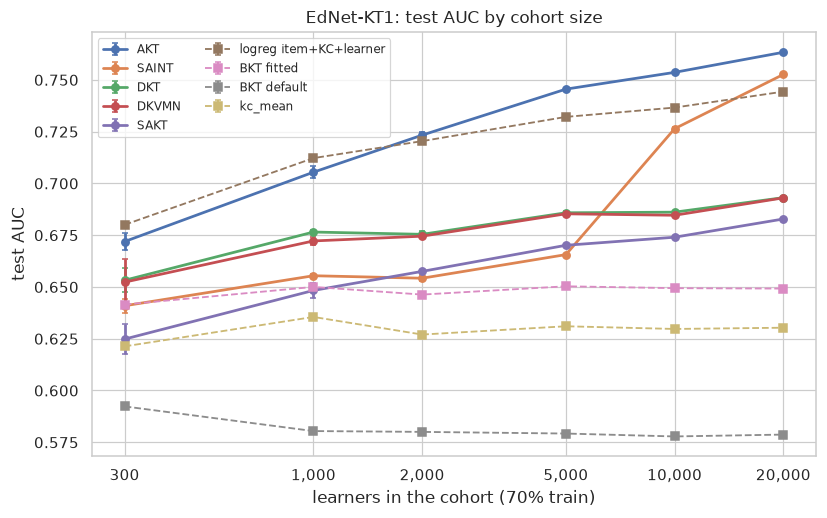

table  -> data/benchmarks/report/tables/ednet_learning_curve.tex


In [5]:
lc = pd.read_csv(BENCH / "ednet_kt1_learning_curve.csv")
wide = lc.pivot_table(index="model", columns="cohort", values="auc_mean").round(4)
display(wide)
fig, ax = plt.subplots(figsize=(8.5, 5))
order = ["AKT", "SAINT", "DKT", "DKVMN", "SAKT", "logreg item+KC+learner", "BKT fitted", "BKT default", "kc_mean"]
for name in [o for o in order if o in set(lc["model"])]:
    g = lc[lc["model"] == name].sort_values("cohort")
    deep = name in L.values()
    ax.errorbar(g["cohort"], g["auc_mean"], yerr=g["auc_sd"].astype(float).fillna(0), marker="o" if deep else "s",
                ls="-" if deep else "--", capsize=2, label=name, lw=1.8 if deep else 1.2)
ax.set_xscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([f"{s:,}" for s in SIZES])
ax.set(xlabel="learners in the cohort (70% train)", ylabel="test AUC", title="EdNet-KT1: test AUC by cohort size")
ax.legend(fontsize=8, ncol=2)
ru.save_fig(fig, "ednet_learning_curve"); plt.show()
curve_tab = wide.reset_index().rename(columns={c: f"{c:,}" for c in wide.columns})
ru.save_table(curve_tab, "ednet_learning_curve", "Test AUC by cohort size (mean of 3 seeds for deep models)",
              "tab:ednet-curve", digits=4, size="footnotesize")

### Paired differences of the deep models, by cohort
Same learner bootstrap as section 2, per cohort. Cell: difference [95% interval]. An interval that excludes 0 marks a difference larger than test-learner sampling noise (not seed or split variance).

In [6]:
WANT = ["AKT − SAINT", "AKT − DKVMN", "SAINT − SAKT", "DKVMN − DKT", "SAINT − Logistic regression", "DKVMN − Logistic regression"]
rows = []
for n in SIZES:
    ev = BENCH / f"ednet_kt1_{n}/kt/artifacts/evaluation"
    if not (ev / "hardening_paired_auc.csv").exists():
        continue
    pr = hardening_tables(ev)[2].set_index("A - B")
    row = {"learners": n}
    for w in WANT:
        if w in pr.index:
            r = pr.loc[w]
            row[w] = f"{r['AUC diff']:+.3f} [{r['CI95_low']:.3f}, {r['CI95_high']:.3f}]"
    rows.append(row)
pbc = pd.DataFrame(rows)
display(pbc)
ru.save_table(pbc[["learners"] + WANT[:4]], "ednet_paired_by_cohort",
              "Paired AUC differences between deep models by cohort size (learner bootstrap, 95\\% interval)",
              "tab:ednet-paired-by-cohort", size="scriptsize")

,learners,AKT − SAINT,AKT − DKVMN,SAINT − SAKT,DKVMN − DKT,SAINT − Logistic regression,DKVMN − Logistic regression
0,300,"+0.029 [0.014, 0.046]","+0.012 [0.001, 0.023]","+0.012 [-0.017, 0.039]","+0.004 [-0.013, 0.020]","-0.033 [-0.060, -0.010]","-0.016 [-0.034, -0.001]"
1,1000,"+0.052 [0.042, 0.062]","+0.033 [0.026, 0.041]","+0.004 [-0.009, 0.018]","-0.004 [-0.009, 0.001]","-0.053 [-0.064, -0.043]","-0.034 [-0.043, -0.025]"
2,2000,"+0.070 [0.063, 0.078]","+0.049 [0.043, 0.056]","-0.006 [-0.013, -0.000]","-0.001 [-0.005, 0.002]","-0.063 [-0.072, -0.055]","-0.042 [-0.050, -0.035]"
3,5000,"+0.077 [0.072, 0.082]","+0.059 [0.056, 0.064]","-0.004 [-0.008, -0.000]","-0.001 [-0.003, 0.000]","-0.062 [-0.067, -0.056]","-0.044 [-0.048, -0.040]"
4,10000,"+0.015 [0.014, 0.016]","+0.068 [0.065, 0.071]","+0.062 [0.059, 0.065]","-0.002 [-0.003, -0.001]","+0.004 [0.002, 0.005]","-0.050 [-0.053, -0.046]"
5,20000,"+0.007 [0.007, 0.008]","+0.070 [0.068, 0.072]","+0.071 [0.069, 0.073]","-0.001 [-0.002, -0.000]","+0.013 [0.012, 0.014]","-0.049 [-0.052, -0.047]"


table  -> data/benchmarks/report/tables/ednet_paired_by_cohort.tex


## 4. Calibration (reliability, mean of 3 seeds)

figure -> data/benchmarks/report/figures/ednet_reliability.png


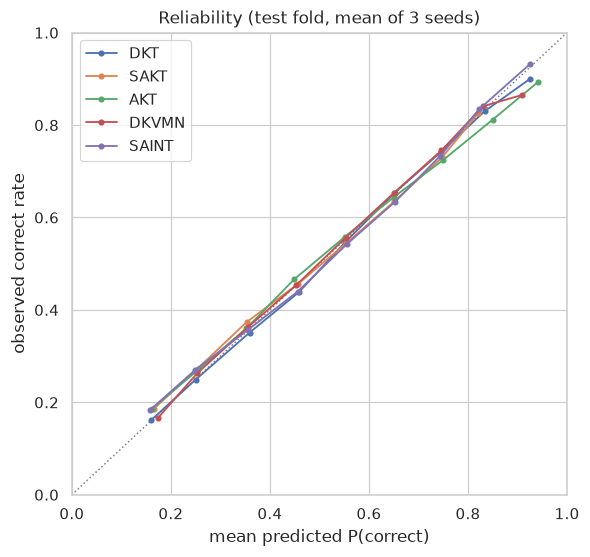

In [7]:
kt = BENCH / f"ednet_kt1_{MAIN}/kt"
have_pykt = (kt / "pykt/test_sequences.csv").exists()
if have_pykt:
    pa = per_answer_frame(kt, M)
    fig, rel = reliability(pa, [m for m in M if m in pa])
    ru.save_fig(fig, "ednet_reliability"); plt.show()
else:
    print("pykt/test_sequences.csv missing: download the cohort folders from Drive (see notebook 13).")

## 5. Where the models differ: position, TOEIC part, unseen items
AUC within groups of test answers, from each model's probabilities averaged over its 3 seeds (so slightly above the per-seed means of section 1). *Position* is the answer's index in the learner's sequence: answers 2–10 are the cold-start case the course is in for most learners.

In [8]:
if have_pykt:
    mods = [m for m in M if m in pa]
    pa["position bin"] = analysis.position_bin(pa["position"])
    by_pos = analysis.auc_by(pa, mods, "position bin").rename(columns=L)
    by_part = analysis.auc_by(pa, mods, "kc_dimension").rename(columns={**L, "kc_dimension": "TOEIC part"})
    pa["item in train"] = pa["item_seen_in_train"].map({True: "seen", False: "unseen"})
    by_seen = analysis.auc_by(pa, mods, "item in train").rename(columns=L)
    for t in (by_pos, by_part, by_seen): display(t)
    ru.save_table(by_pos, "ednet_auc_by_position", f"Test AUC by answer position ({MAIN:,} cohort; probabilities averaged over 3 seeds)", "tab:ednet-auc-position", digits=4)
    ru.save_table(by_part, "ednet_auc_by_part", f"Test AUC by TOEIC part ({MAIN:,} cohort; probabilities averaged over 3 seeds)", "tab:ednet-auc-part", digits=4)
    ru.save_table(by_seen, "ednet_auc_by_seen", f"Test AUC on items seen or unseen in training ({MAIN:,} cohort; probabilities averaged over 3 seeds)", "tab:ednet-auc-seen", digits=4)

,position bin,n,correct_rate,DKT,SAKT,AKT,DKVMN,SAINT
0,2-10,9000,0.4889,0.6940,0.6947,0.7321,0.6925,0.7030
1,11-30,19275,0.4950,0.7139,0.7031,0.7439,0.7076,0.7086
2,31-100,32592,0.6453,0.6603,0.6371,0.7323,0.6587,0.6281
3,101-200,27812,0.6576,0.6412,0.6218,0.7328,0.6458,0.6109


,TOEIC part,n,correct_rate,DKT,SAKT,AKT,DKVMN,SAINT
0,part1,9450,0.6766,0.7220,0.7061,0.7747,0.7159,0.7027
1,part2,17364,0.6916,0.6341,0.6157,0.7103,0.6346,0.6220
2,part3,3326,0.5806,0.7224,0.7055,0.7857,0.7154,0.7121
3,part4,6789,0.4357,0.7121,0.6975,0.7501,0.7045,0.7128
4,part5,42343,0.5700,0.6637,0.6475,0.7271,0.6637,0.6409
5,part6,5936,0.6651,0.6557,0.6393,0.7414,0.6539,0.6452
6,part7,3471,0.5439,0.7088,0.6937,0.7750,0.7022,0.7265


,item in train,n,correct_rate,DKT,SAKT,AKT,DKVMN,SAINT
0,seen,88380,0.6002,0.6893,0.6747,0.7476,0.6881,0.6706
1,unseen,299,0.7224,0.6392,0.6185,0.6957,0.6479,0.6165


table  -> data/benchmarks/report/tables/ednet_auc_by_position.tex
table  -> data/benchmarks/report/tables/ednet_auc_by_part.tex
table  -> data/benchmarks/report/tables/ednet_auc_by_seen.tex


## 6. Training cost and convergence

,learners,model,epochs,best_epoch,s_per_epoch,minutes_per_run,params,GPU
0,300,AKT,35.33,25.33,0.49,0.29,318070,T4
1,300,DKT,24.00,14.00,0.12,0.05,186381,T4
2,300,DKVMN,34.00,24.00,0.42,0.24,50113,T4
3,300,SAINT,29.00,19.00,0.25,0.12,1029441,T4
4,300,SAKT,18.33,8.33,0.13,0.04,90369,T4
5,1000,AKT,44.33,34.33,1.58,1.17,321009,T4
6,1000,DKT,16.67,6.67,0.31,0.09,186766,T4
7,1000,DKVMN,28.67,18.67,1.12,0.54,50305,T4
8,1000,SAINT,21.67,11.67,0.77,0.28,1372993,T4
9,1000,SAKT,23.33,13.33,0.41,0.16,90561,T4


table  -> data/benchmarks/report/tables/ednet_cost.tex
figure -> data/benchmarks/report/figures/ednet_convergence.png


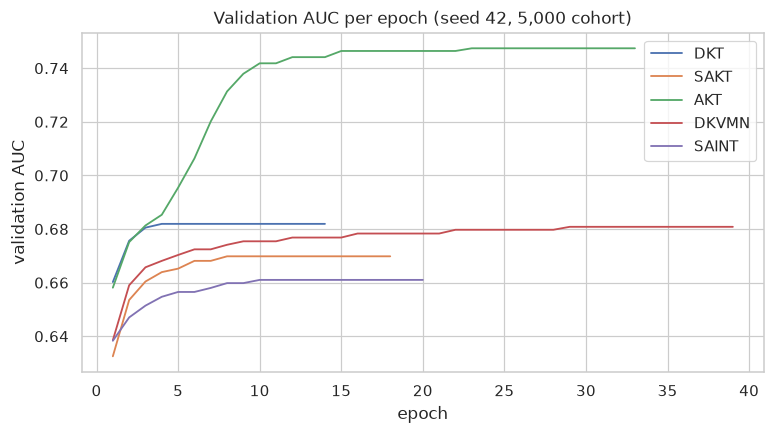

In [9]:
rows = []
for n in SIZES:
    art = BENCH / f"ednet_kt1_{n}/kt/artifacts"
    if art.exists():
        t = analysis.run_table(art, M); t.insert(0, "learners", n); rows.append(t)
runs = pd.concat(rows, ignore_index=True)
# PyTorch CUDA build recorded in run_summary.json -> machine (colab_environment.json: T4 used cu130)
GPU_OF_BUILD = {"cu130": "T4", "cu126": "1070 Ti"}
cost = runs.groupby(["learners", "model"]).agg(
    epochs=("epochs_run", "mean"), best_epoch=("best_epoch", "mean"),
    s_per_epoch=("seconds_per_epoch", "mean"), minutes_per_run=("train_seconds", lambda s: s.mean() / 60),
    params=("n_params", "first"),
    GPU=("torch_version", lambda v: " + ".join(sorted({GPU_OF_BUILD.get(str(x).rsplit("+", 1)[-1], str(x)) for x in v})))).reset_index()
display(cost.round(2))
ru.save_table(cost[cost["learners"].isin([MAIN, 20000])].round(2).rename(columns={
                  "best_epoch": "best", "s_per_epoch": "s/epoch", "minutes_per_run": "min/run"}), "ednet_cost",
              "Training cost per run (mean of 3 seeds)", "tab:ednet-cost", digits=1, size="footnotesize",
              note="GPU from each run's recorded PyTorch build: T4 = Colab Tesla T4, 1070 Ti = local GTX 1070 Ti. Times on different GPUs are not comparable.")
fig, ax = plt.subplots(figsize=(8, 4))
for m in M:
    log = BENCH / f"ednet_kt1_{MAIN}/kt/artifacts/{m}/seed42/train.log"
    if log.exists():
        c = analysis.training_curve(log); ax.plot(c["epoch"], c["valid_auc"], label=L[m])
ax.set(xlabel="epoch", ylabel="validation AUC", title=f"Validation AUC per epoch (seed 42, {MAIN:,} cohort)")
ax.legend(); ru.save_fig(fig, "ednet_convergence"); plt.show()

## 7. Copy figures and tables into the thesis

In [10]:
ru.sync_to_thesis()

14 figures -> thesis_docs/reports/DACN_HK261/figures/kt
30 tables -> thesis_docs/reports/DACN_HK261/tables/kt
